In [26]:
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers, models

In [27]:
np.random.seed(42)
tf.random.set_seed(42)

In [28]:
time = np.arange(2000)
series = (
    np.sin(time * 0.02)
    +
    0.3 * np.sin(time * 0.05)
)
series

array([0.        , 0.03499242, 0.06993936, ..., 0.59490173, 0.59421031,
       0.59365278], shape=(2000,))

In [29]:
series

array([0.        , 0.03499242, 0.06993936, ..., 0.59490173, 0.59421031,
       0.59365278], shape=(2000,))

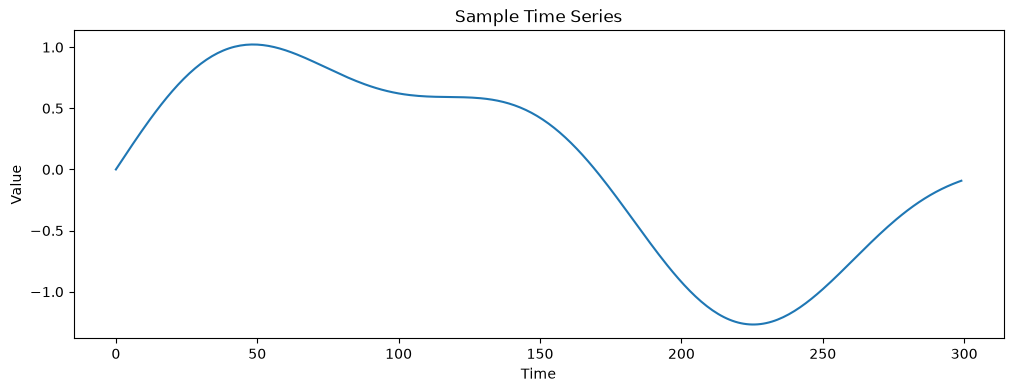

In [30]:
series = series.astype("float32")

plt.figure(figsize=(12, 4))
plt.plot(time[:300], series[:300])
plt.title("Sample Time Series")
plt.xlabel("Time")
plt.ylabel("Value")
plt.show()

In [31]:
len(series)

2000

In [32]:
window_size = 30

X = []
y = []
target_indices = []

for i in range(len(series) - window_size):
    X.append(series[i : i + window_size])
    y.append(series[i + window_size])
    target_indices.append(i + window_size)

In [33]:
X = np.array(X, dtype='float32')
y = np.array(y, dtype='float32')
target_indices = np.array(target_indices)

print(X)

[[0.         0.03499242 0.06993936 ... 0.806853   0.8268211  0.84583783]
 [0.03499242 0.06993936 0.10479545 ... 0.8268211  0.84583783 0.86389095]
 [0.06993936 0.10479545 0.13951549 ... 0.84583783 0.86389095 0.8809703 ]
 ...
 [0.7516791  0.7417948  0.73214734 ... 0.59802073 0.5967839  0.5957517 ]
 [0.7417948  0.73214734 0.7227567  ... 0.5967839  0.5957517  0.59490174]
 [0.73214734 0.7227567  0.7136413  ... 0.5957517  0.59490174 0.5942103 ]]


In [34]:
print(y)

[0.86389095 0.8809703  0.89706755 ... 0.59490174 0.5942103  0.5936528 ]


In [35]:
print(X.shape)
print(y.shape)

(1970, 30)
(1970,)


In [36]:
X = X.reshape(X.shape[0], window_size, 1)
print(X.shape)
print(y.shape)

(1970, 30, 1)
(1970,)


In [37]:
split_index = int(len(series) * 0.80)
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

print(split_index)
print(train_mask)
print(test_mask)

1600
[ True  True  True ... False False False]
[False False False ...  True  True  True]


In [38]:
X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print(X_train)
print(y_train)
print(X_test)
print(y_test)

[[[ 0.        ]
  [ 0.03499242]
  [ 0.06993936]
  ...
  [ 0.806853  ]
  [ 0.8268211 ]
  [ 0.84583783]]

 [[ 0.03499242]
  [ 0.06993936]
  [ 0.10479545]
  ...
  [ 0.8268211 ]
  [ 0.84583783]
  [ 0.86389095]]

 [[ 0.06993936]
  [ 0.10479545]
  [ 0.13951549]
  ...
  [ 0.84583783]
  [ 0.86389095]
  [ 0.8809703 ]]

 ...

 [[-0.01925004]
  [-0.01408901]
  [-0.00901012]
  ...
  [ 0.17253152]
  [ 0.18468423]
  [ 0.19735241]]

 [[-0.01408901]
  [-0.00901012]
  [-0.00398412]
  ...
  [ 0.18468423]
  [ 0.19735241]
  [ 0.21054135]]

 [[-0.00901012]
  [-0.00398412]
  [ 0.00101841]
  ...
  [ 0.19735241]
  [ 0.21054135]
  [ 0.22425465]]]
[0.86389095 0.8809703  0.89706755 ... 0.21054135 0.22425465 0.2384942 ]
[[[-0.00398412]
  [ 0.00101841]
  [ 0.00602694]
  ...
  [ 0.21054135]
  [ 0.22425465]
  [ 0.2384942 ]]

 [[ 0.00101841]
  [ 0.00602694]
  [ 0.01107094]
  ...
  [ 0.22425465]
  [ 0.2384942 ]
  [ 0.25326008]]

 [[ 0.00602694]
  [ 0.01107094]
  [ 0.01617978]
  ...
  [ 0.2384942 ]
  [ 0.25326008]
  [ 

In [39]:
print(len(X_train))
print(len(X_test))

1570
400


In [40]:
model = models.Sequential([
    layers.Input(shape=(window_size, 1)),
    layers.SimpleRNN(32, activation='tanh'),
    layers.Dense(1)
])

model.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=0.001),
    loss = "mse",
    metrics=['mae']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_2 (SimpleRNN)        │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
history = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=32,
    validation_split=0.20,
    shuffle=False,
    verbose=0
)

test_loss, test_mae = model.evaluate(X_test, y_test, verbose=0)

print("=" * 20, "TEST RESULTS", "="*20)
print("Test MSE", round(float(test_loss), 5))
print("Test MAE", round(float(test_mae), 5))

==================== TEST RESULTS ====================
Test MSE 0.00022
Test MAE 0.01181


In [42]:
predictions = model.predict(X_test, verbose=0).flatten()
print("First Predictions")
for i in range(5):
    print(
        f"Actual : {y_test[i]:.4f} |"
        f"Predicted : {predictions[i]:.4f}"
    )

First Predictions
Actual : 0.2533 |Predicted : 0.2512
Actual : 0.2686 |Predicted : 0.2661
Actual : 0.2844 |Predicted : 0.2814
Actual : 0.3007 |Predicted : 0.2973
Actual : 0.3175 |Predicted : 0.3136


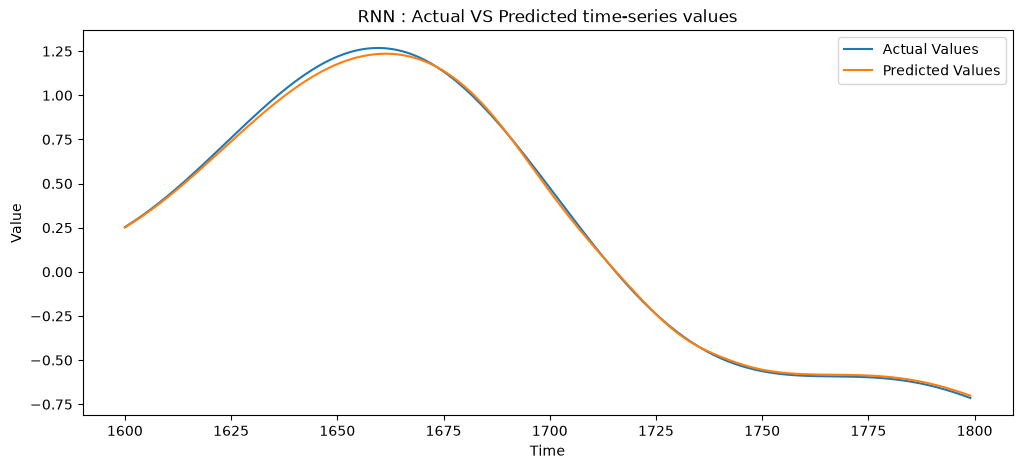

In [43]:
plt.figure(figsize=(12, 5))
plt.plot(
    target_indices[test_mask][:200],
    y_test[:200],
    label="Actual Values"
)
plt.plot(
    target_indices[test_mask][:200],
    predictions[:200],
    label="Predicted Values"
)

plt.title("RNN : Actual VS Predicted time-series values")
plt.xlabel("Time")
plt.ylabel("Value")
plt.legend()
plt.show()

In [ ]:
latest_window = series[-window_size:].reshape(1, window_size, 1)
next_prediction = model.predict(latest_window, verbose=0)[0, 0]¸
print("\nLatest Observed Value : ", round(float(series[-1]), 4))
print("\nPredicted Next Value : ", round(float(next_prediction), 4))


Latest Observed Value :  0.5937

Predicted Next Value :  0.5869
